# Proyek Analisis Data: E-Commerce
- **Nama:** Radithya Danutirta
- **Email:** ds288b6y1465@student.devacademy.id
- **ID Dicoding:** radithya_danutirta_HKkL

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan revenue tertinggi dan terendah dari order berstatus *delivered* selama September 2016 – Agustus 2018, dan berapa persen kontribusi 5 kategori teratas terhadap total revenue?
- **Pertanyaan 2:** Berapa selisih rata-rata review score antara order yang terlambat dan yang tepat waktu selama September 2016 – Agustus 2018, dan seberapa kuat korelasi durasi pengiriman (delivery_time) dengan review score?
- **Pertanyaan 3:** Bagaimana segmentasi pelanggan unik berdasarkan RFM (recency, frequency, monetary) selama September 2016 – Agustus 2018, dan segmen mana yang menyumbang spending terbesar sehingga layak jadi target retensi?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
cust_df = pd.read_csv('customers_dataset.csv')
cust_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [3]:
geo_df = pd.read_csv('geolocation_dataset.csv')
geo_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [4]:
order_items_df = pd.read_csv('order_items_dataset.csv')
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [5]:
order_payments_df = pd.read_csv('order_payments_dataset.csv')
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [6]:
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [7]:
orders_df = pd.read_csv('orders_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
products_df = pd.read_csv('products_dataset.csv')
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
products_cat_name_df = pd.read_csv('product_category_name_translation.csv')
products_cat_name_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [10]:
sellers_df = pd.read_csv('sellers_dataset.csv')
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [11]:
cust_df['customer_unique_id'].nunique()

96096

**Insight:** (Opsional)
- **Berhasil Memuat Data**: Seluruh 9 tabel dataset e-commerce (customers, orders, order_items, order_payments, order_reviews, products, sellers, geolocation, dan product_category_name_translation) telah berhasil dimuat ke dalam Pandas DataFrame.
- **Gambaran Volume Data**:
  - Dataset transaksi utama (`orders_df`) mencakup 99.441 data pesanan.
  - Dataset detail produk transaksi (`order_items_df`) mencakup 112.650 item.
  - Dataset pelanggan (`cust_df`) mencakup 99.441 baris `customer_id`. Satu `customer_id` mewakili satu order, jadi jumlah pelanggan unik sebenarnya dilihat dari `customer_unique_id`.
  - Dataset ulasan (`order_reviews_df`) mencakup 99.224 ulasan dari pelanggan.
- **Kesiapan Data**: Seluruh DataFrame siap untuk melangkah ke tahap selanjutnya, yaitu **Assessing Data**, untuk mengevaluasi tipe data, *missing values*, dan duplikasi pada masing-masing tabel.

### Assessing Data

#### Identifying ... problem

In [12]:
cust_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [13]:
cust_df.describe()

,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000


In [14]:
cust_df.isnull().sum()

,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


In [15]:
cust_df.duplicated().sum()

np.int64(0)

In [16]:
geo_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [17]:
geo_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02


In [18]:
geo_df.isnull().sum()

,0
geolocation_zip_code_prefix,0
geolocation_lat,0
geolocation_lng,0
geolocation_city,0
geolocation_state,0


In [19]:
geo_df.duplicated().sum()

np.int64(261831)

In [20]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [21]:
order_items_df.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [22]:
order_items_df.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [23]:
order_items_df.duplicated().sum()

np.int64(0)

In [24]:
order_payments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [25]:
order_payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [26]:
order_payments_df.isnull().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [27]:
order_payments_df.duplicated().sum()

np.int64(0)

In [28]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [29]:
order_reviews_df.describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [30]:
order_reviews_df.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [31]:
order_reviews_df.duplicated().sum()

np.int64(0)

In [32]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [33]:
orders_df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [34]:
orders_df.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [35]:
orders_df.duplicated().sum()

np.int64(0)

In [36]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [37]:
products_df.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [38]:
products_df.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [39]:
products_df.duplicated().sum()

np.int64(0)

In [40]:
products_cat_name_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [41]:
products_cat_name_df.describe()

,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


In [42]:
products_cat_name_df.isnull().sum()

,0
product_category_name,0
product_category_name_english,0


In [43]:
products_cat_name_df.duplicated().sum()

np.int64(0)

In [44]:
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [45]:
sellers_df.describe()

,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000


In [46]:
sellers_df.isnull().sum()

,0
seller_id,0
seller_zip_code_prefix,0
seller_city,0
seller_state,0


In [47]:
sellers_df.duplicated().sum()

np.int64(0)

Hasil Assessing Data

1. `orders_df`
- **Missing Values:**
  - `order_approved_at`: 160 data hilang.
  - `order_delivered_carrier_date`: 1.783 data hilang.
  - `order_delivered_customer_date`: 2.965 data hilang.
- **Incorrect Data Type:**
  - Kolom `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` masih ber-tipe `object` (string), seharusnya diubah menjadi `datetime`.

2. `order_items_df`
- **Incorrect Data Type:**
  - Kolom `shipping_limit_date` masih ber-tipe `object` (string), seharusnya diubah menjadi `datetime`.

3. `order_reviews_df`
- **Missing Values:**
  - `review_comment_title`: 87.656 data hilang.
  - `review_comment_message`: 58.247 data hilang.
  *(Catatan: Missing values pada komentar ulasan tergolong wajar karena tidak semua pelanggan menuliskan ulasan teks).*
- **Incorrect Data Type:**
  - Kolom `review_creation_date` dan `review_answer_timestamp` masih ber-tipe `object` (string), seharusnya diubah menjadi `datetime`.

4. `products_df`
- **Missing Values:**
  - `product_category_name`, `product_name_lenght`, `product_description_lenght`, dan `product_photos_qty`: 610 data hilang.
  - `product_weight_g`, `product_length_cm`, `product_height_cm`, dan `product_width_cm`: 2 data hilang.

5. `geo_df` (Geolocation)
- **Duplicate Data:**
  - Terdapat **261.831 baris data duplikat** yang perlu dibersihkan/dihapus.

**Steps to Take:**
1. **Pembersihan Duplikat (`geo_df`)**: Menghapus 261.831 baris data duplikat pada geolocation dataset menggunakan method `.drop_duplicates()`.
2. **Koreksi Tipe Data (Datetime)**: Converting/mengubah tipe data kolom bertema tanggal dan waktu dari `object` menjadi `datetime` menggunakan `pd.to_datetime()` pada:
   - `orders_df`: `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`.
   - `order_items_df`: `shipping_limit_date`.
   - `order_reviews_df`: `review_creation_date`, `review_answer_timestamp`.
3. **Penanganan Missing Values (`products_df` & `orders_df`)**:
   - Membiarkan missing values pada `orders_df` (timestamp pengiriman/persetujuan) dan `order_reviews_df` (teks ulasan) karena mencerminkan kondisi riil transaksi (order belum dikirim/pelanggan tidak mengisi teks ulasan).
   - Mengisi (*imputation*) missing values pada nama kategori produk di `products_df` dengan nilai `"unknown"` agar tidak mengganggu analisis agregasi.

**Insight:** (Opsional)
- **Data Quality Assessment**: Secara keseluruhan, dataset e-commerce ini memiliki kualitas data yang sangat baik pada aspek entitas utama (seperti data pelanggan, pembayaran, dan penjual yang 100% lengkap tanpa duplikat).
- **Inkonsistensi Tipe Data**: Masalah utama terletak pada tipe data temporal (tanggal/waktu) yang terdeteksi sebagai tipe objek (string). Hal ini perlu diperbaiki agar nantinya bisa dilakukan analisis tren waktu (seperti bulanan atau harian).
- **Redundansi Geolocation**: Tingginya angka duplikat pada `geo_df` terjadi karena satu kode pos mencakup banyak titik koordinat lokasi/kelurahan, sehingga pembersihan duplikat sangat penting untuk menghemat memori dan mempercepat proses merging.
- **Kondisi Data Pasca Cleaning**: Setelah proses koreksi tipe data, penghapusan duplikat, dan penanganan missing value dilakukan, seluruh DataFrame siap digabungkan (*merge*) untuk masuk ke tahap **Exploratory Data Analysis (EDA)**.

### Cleaning Data

#### Fixing ... problem

In [48]:
geo_df = geo_df.drop_duplicates()
geo_df.duplicated().sum()

np.int64(0)

In [49]:
geo_df.reset_index(drop=True, inplace=True)
geo_df

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP
...,...,...,...,...,...
738327,99965,-28.180655,-52.034367,agua santa,RS
738328,99950,-28.072188,-52.011272,tapejara,RS
738329,99950,-28.068864,-52.012964,tapejara,RS
738330,99950,-28.068639,-52.010705,tapejara,RS


orders_df
Missing Values:
- order_approved_at: 160 data hilang.
- order_delivered_carrier_date: 1.783 data hilang.
- order_delivered_customer_date: 2.965 data hilang.
Incorrect Data Type:
- Kolom order_purchase_timestamp, order_approved_at order_delivered_carrier_date, order_delivered_customer_date, dan order_estimated_delivery_date masih ber-tipe object (string), seharusnya diubah menjadi datetime. (done)

In [50]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [51]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [52]:
orders_df.groupby('order_status')['order_id'].count()

,order_id
order_status,
approved,2
canceled,625
created,5
delivered,96478
invoiced,314
processing,301
shipped,1107
unavailable,609


In [53]:
orders_df.nunique()

,0
order_id,99441
customer_id,99441
order_status,8
order_purchase_timestamp,98875
order_approved_at,90733
order_delivered_carrier_date,81018
order_delivered_customer_date,95664
order_estimated_delivery_date,459


In [54]:
column = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in column:
  orders_df[col] = pd.to_datetime(orders_df[col])
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [55]:
delivery_time = orders_df['order_delivered_customer_date'] - orders_df['order_purchase_timestamp']
orders_df['delivery_time'] = round(delivery_time.dt.total_seconds()/86400, 2)
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87


In [56]:
approve = orders_df['order_approved_at'] - orders_df['order_purchase_timestamp']
orders_df['approve_time'] = round(approve.dt.total_seconds()/3600, 2)
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03


In [57]:
orders_df['is_late'] = np.where(
    orders_df['order_delivered_customer_date'].isna(),
    np.nan,
    orders_df['order_delivered_customer_date'] > orders_df['order_estimated_delivery_date']
)
orders_df['is_late'] = orders_df['is_late'].astype('boolean')

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,False


In [58]:
orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18,NaN,0.21,<NA>
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16,NaN,0.34,<NA>
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30,NaN,0.17,<NA>
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30,NaN,0.16,<NA>
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24,NaN,0.26,<NA>
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23,NaN,0.13,<NA>
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26,NaN,0.45,<NA>
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19,NaN,0.34,<NA>


In [59]:
drop_nat_on_not_delivered = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
].index

orders_df = orders_df.drop(index=drop_nat_on_not_delivered)

In [60]:
orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_delivered_customer_date'].isna())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late


In [61]:
orders_df['order_status'].value_counts()

,count
order_status,
delivered,96470
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [62]:
orders_df.groupby('order_status').count().sort_values(by='order_id', ascending=False)

,order_id,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
order_status,,,,,,,,,,
delivered,96470,96470,96470,96456,96469,96470,96470,96470,96456,96470
shipped,1107,1107,1107,1107,1107,0,1107,0,1107,0
canceled,625,625,625,484,75,6,625,6,484,6
unavailable,609,609,609,609,0,0,609,0,609,0
invoiced,314,314,314,314,0,0,314,0,314,0
processing,301,301,301,301,0,0,301,0,301,0
created,5,5,5,0,0,0,5,0,0,0
approved,2,2,2,2,0,0,2,0,2,0


In [63]:
orders_df.isna().sum().sort_values(ascending=False)

,0
is_late,2957
delivery_time,2957
order_delivered_customer_date,2957
order_delivered_carrier_date,1782
approve_time,160
order_approved_at,160
order_id,0
order_status,0
customer_id,0
order_purchase_timestamp,0


In [64]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,False


Sisa tabel di daftar cleaning yang belum dieksekusi:

order_items_df: Ubah shipping_limit_date ke datetime.

order_reviews_df: Ubah review_creation_date dan review_answer_timestamp ke datetime.

products_df: Imputasi product_category_name yang kosong dengan "unknown" (dan tentukan perlakuan untuk 610 baris dimensi/nama yang NaN serta 2 baris berat/ukuran yang kosong).

In [65]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [66]:
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


In [67]:
order_items_df.reset_index(drop=True, inplace=True)

In [68]:
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [69]:
col = ['review_creation_date', 'review_answer_timestamp']
for column in col:
  order_reviews_df[column] = pd.to_datetime(order_reviews_df[column])
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  object        
 1   order_id                 99224 non-null  object        
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  object        
 4   review_comment_message   40977 non-null  object        
 5   review_creation_date     99224 non-null  datetime64[ns]
 6   review_answer_timestamp  99224 non-null  datetime64[ns]
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 5.3+ MB


In [70]:
order_reviews_df.isna().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [71]:
order_reviews_df.duplicated().sum()

np.int64(0)

In [72]:
order_reviews_df.head(10)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13,2018-04-16 00:39:37
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,NaN,NaN,2017-07-16,2017-07-18 19:30:34
7,7c6400515c67679fbee952a7525281ef,c31a859e34e3adac22f376954e19b39d,5,NaN,NaN,2018-08-14,2018-08-14 21:36:06
8,a3f6f7f6f433de0aefbb97da197c554c,9c214ac970e84273583ab523dfafd09b,5,NaN,NaN,2017-05-17,2017-05-18 12:05:37
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22,2018-05-23 16:45:47


products_df: Imputasi product_category_name yang kosong dengan "unknown" (dan tentukan perlakuan untuk 610 baris dimensi/nama yang NaN serta 2 baris berat/ukuran yang kosong).

In [73]:
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [74]:
products_df.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [75]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [76]:
products_df[products_df['product_category_name'].isna()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [77]:
products_df[(products_df['product_category_name'].isna()) & (products_df['product_length_cm'].notna())]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [78]:
# transaksi di order_items_df yang pakai 610 produk anomali ini
missing_products = products_df[products_df['product_category_name'].isna()]['product_id']
affected_orders = order_items_df[order_items_df['product_id'].isin(missing_products)]
print(f"Jumlah item transaksi terdampak: {len(affected_orders)}")

Jumlah item transaksi terdampak: 1603


transaksi yang terdampak pada product yang nama produknya null ada sebanyak  1603 produk, jadi kita tidak bisa menghapus produk ini. Saya mengubah menjadi unknown

In [79]:
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')
products_df[products_df['product_category_name'] == 'unknown']

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,unknown,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,unknown,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,unknown,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,unknown,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,unknown,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,unknown,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,unknown,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,unknown,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,unknown,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [80]:
products_df[products_df['product_category_name'].isna()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm


## Exploratory Data Analysis (EDA)

### Explore ...

In [81]:
# Verifikasi hasil pembersihan data sebelum masuk ke tahap EDA
print("=== VERIFIKASI DATA PASCA CLEANING ===\n")

# 1. Cek Duplikat Geolocation
print(f"Duplikat pada geo_df: {geo_df.duplicated().sum()}")

# 2. Cek tipe data temporal pada orders_df
print("\nTipe data tanggal pada orders_df:")
print(orders_df[['order_purchase_timestamp', 'order_approved_at', 'order_delivered_customer_date']].dtypes)

# 3. Cek missing values pada kategori produk setelah di-imputasi
print(f"\nMissing values kategori di products_df: {products_df['product_category_name'].isnull().sum()}")
print(f"Jumlah produk dengan kategori 'unknown': {len(products_df[products_df['product_category_name'] == 'unknown'])}")

# 4. Tampilkan informasi dasar orders_df yang siap digunakan
print("\nDimensi orders_df sekarang:", orders_df.shape)

=== VERIFIKASI DATA PASCA CLEANING ===

Duplikat pada geo_df: 0

Tipe data tanggal pada orders_df:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_customer_date    datetime64[ns]
dtype: object

Missing values kategori di products_df: 0
Jumlah produk dengan kategori 'unknown': 610

Dimensi orders_df sekarang: (99433, 11)


In [82]:
cust_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [83]:
cust_df.groupby('customer_city')['customer_id'].nunique().sort_values(ascending=False)

,customer_id
customer_city,
sao paulo,15540
rio de janeiro,6882
belo horizonte,2773
brasilia,2131
curitiba,1521
...,...
agisse,1
vieiras,1
bertopolis,1


In [84]:
cust_df.groupby('customer_state')['customer_id'].nunique().sort_values(ascending=False)

,customer_id
customer_state,
SP,41746
RJ,12852
MG,11635
RS,5466
PR,5045
SC,3637
BA,3380
DF,2140
ES,2033


In [85]:
geo_df.describe()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,738332.000000,738332.000000,738332.000000
mean,38316.086800,-20.998353,-46.461098
std,30632.496675,5.892315,4.393705
min,1001.000000,-36.605374,-101.466766
25%,12600.000000,-23.603061,-48.867822
50%,29144.000000,-22.873588,-46.647278
75%,65950.000000,-19.923336,-43.836974
max,99990.000000,45.065933,121.105394


In [86]:
geo_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 738332 entries, 0 to 738331
Data columns (total 5 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   geolocation_zip_code_prefix  738332 non-null  int64  
 1   geolocation_lat              738332 non-null  float64
 2   geolocation_lng              738332 non-null  float64
 3   geolocation_city             738332 non-null  object 
 4   geolocation_state            738332 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 28.2+ MB


In [87]:
geo_clean = geo_df.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean',
    'geolocation_city': 'first',
    'geolocation_state': 'first'
}).reset_index()

geo_clean.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.550227,-46.634039,sao paulo,SP
1,1002,-23.547657,-46.634991,sao paulo,SP
2,1003,-23.549000,-46.635582,sao paulo,SP
3,1004,-23.549829,-46.634792,sao paulo,SP
4,1005,-23.549547,-46.636406,sao paulo,SP


In [88]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [89]:
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


In [90]:
order_items_df.groupby('order_id')['order_item_id'].count().sort_values(ascending=False).reset_index()
# junmlah item yang dipesan per sekali order

,order_id,order_item_id
0,8272b63d03f5f79c56e9e4120aec44ef,21
1,1b15974a0141d54e36626dca3fdc731a,20
2,ab14fdcfbe524636d65ee38360e22ce8,20
3,9ef13efd6949e4573a18964dd1bbe7f5,15
4,428a2f660dc84138d969ccd69a0ab6d5,15
...,...,...
98661,5a082b558a3798d3e36d93bfa8ca1eae,1
98662,5a07264682e0b8fbb3f166edbbffc6e8,1
98663,5a071192a28951b76774e5a760c8c9b7,1
98664,5a06fc966a12b41bf401b344464fd4b1,1


In [91]:
order_items_df.groupby('seller_id')['product_id'].nunique().sort_values(ascending=False)
# jumlah produk yang terjual per satu seller

,product_id
seller_id,
4a3ca9315b744ce9f8e9374361493884,399
cca3071e3e9bb7d12640c9fbe2301306,322
d91fb3b7d041e83b64a00a3edfb37e4f,315
fa1c13f2614d7b5c4749cbc52fecda94,289
7142540dd4c91e2237acb7e911c4eba2,266
...,...
c0f3eea2e14555b6faeea3dd58c1b1c3,1
c360e4787614ed31ac7a2f95d3b22dc6,1
c12d7463a579237ffb9248bd7cff378b,1


In [92]:
cust_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [93]:
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


- order_id: ID unik transaksi yang menghubungkan tabel ini ke orders_df.

- payment_sequential: Urutan pembayaran dalam satu pesanan. Jika pelanggan membayar satu pesanan menggunakan lebih dari satu metode sekaligus (misalnya sebagian pakai voucher, sisanya pakai credit_card), maka akan muncul beberapa baris dengan order_id yang sama dan payment_sequential bernilai 1, 2, 3, ....

- payment_type: Metode pembayaran yang digunakan (seperti credit_card, boleto, voucher, atau debit_card).

- payment_installments: Jumlah tenor cicilan yang dipilih pelanggan (misalnya 8 berarti dicicil 8 kali/bulan, 1 berarti dibayar lunas sekali bayar).

- payment_value: Total nominal uang yang dibayarkan pada urutan pembayaran tersebut (sudah mencakup harga barang ditambah ongkos kirim).

In [94]:
order_payments_df.groupby('payment_type')['payment_installments'].agg(
    jumlah_transaksi='count',
    rata_rata_cicilan='mean',
    tenor_maksimal='max'
).sort_values(by='jumlah_transaksi', ascending=False)

,jumlah_transaksi,rata_rata_cicilan,tenor_maksimal
payment_type,,,
credit_card,76795,3.507155,24
boleto,19784,1.000000,1
voucher,5775,1.000000,1
debit_card,1529,1.000000,1
not_defined,3,1.000000,1


In [95]:
order_payments_df.groupby('order_id').agg({
    'payment_sequential' : 'count',
    'payment_value' : 'sum'
}).sort_values(by='payment_sequential', ascending=False)

,payment_sequential,payment_value
order_id,,
fa65dad1b0e818e3ccc5cb0e39231352,29,457.99
ccf804e764ed5650cd8759557269dc13,26,62.68
285c2e15bebd4ac83635ccc563dc71f4,22,40.85
895ab968e7bb0d5659d16cd74cd1650c,21,161.32
ee9ca989fc93ba09a6eddc250ce01742,19,82.73
...,...,...
56bafc014f8ed2f34cfe598592c65fd8,1,88.92
56ba89857b4e6eb192108f310a81163b,1,197.23
56ba02ddcb5947d6fe4d7816e623e054,1,296.61


order dapat dibayarkan lebih dari 1x pembayaran, biasanya penggunaan voucher yang menyebabkan pembayaran hingga 29x. table ini memerlukan grouping per order id agar tidak terjadi duplikat

In [96]:
order_payments_df['payment_type'].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [97]:
order_payments_df[order_payments_df['payment_type'] == "not_defined"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [98]:
cancel = order_payments_df[order_payments_df['payment_type'] == "not_defined"]['order_id']
status_order = orders_df[orders_df['order_id'].isin(cancel)]['order_status']
print(status_order)

1130     canceled
39919    canceled
40235    canceled
Name: order_status, dtype: object


Payment value yang not_defined pada order_payments merupakan order yang berstatus canceled

In [99]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,False


In [100]:
order_payments_df.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [101]:
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


In [102]:
response = order_reviews_df['review_answer_timestamp'] - order_reviews_df['review_creation_date']
order_reviews_df['response_time'] = round(response.dt.total_seconds()/3600, 2)

order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,response_time
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59,21.78
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13,27.09
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24,38.61
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06,22.04
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53,34.45


In [103]:
order_reviews_df.groupby('review_score')['review_comment_message'].size()

,review_comment_message
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [104]:
review_analysis = order_reviews_df.groupby('review_score')['review_comment_message'].agg(
    total_review = 'size',
    beserta_komentar = 'count'
)

review_analysis['persentase'] = round(review_analysis['beserta_komentar'] / review_analysis['total_review'] * 100,2)
review_analysis

,total_review,beserta_komentar,persentase
review_score,,,
1,11424,8745,76.55
2,3151,2145,68.07
3,8179,3557,43.49
4,19142,5976,31.22
5,57328,20554,35.85


review score 1 selalu disertai dengan komentar,  kemungkinan besar ini adalah hasil keluhan dari produk yang diterima

In [105]:
round(order_reviews_df['review_score'].value_counts(normalize=True) * 100,2)

,proportion
review_score,
5,57.78
4,19.29
1,11.51
3,8.24
2,3.18


order reviews didominasi oleh review bintang 5 dengan proporsi 57.8%

orders_dataset

In [106]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,False


In [107]:
orders_df.value_counts('order_status')

,count
order_status,
delivered,96470
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [108]:
orders_df['is_late'] = np.where(
    orders_df['order_delivered_customer_date'].isna(),
    np.nan,
    orders_df['order_delivered_customer_date'] > orders_df['order_estimated_delivery_date']
)
orders_df['is_late'] = orders_df['is_late'].astype('boolean')

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,False


In [109]:
# Cek apakah ada waktu pengiriman atau approval yang negatif (< 0)
orders_df[
    (orders_df['delivery_time'] < 0) |
    (orders_df['approve_time'] < 0)
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,is_late


In [110]:
products_cat_name_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [111]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [112]:
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [113]:
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


merge

In [114]:
payment_agg_df = order_payments_df.groupby('order_id').agg(
    total_pembayaran = ('payment_value', 'sum'),
    jumlah_pembayaran = ('payment_sequential', 'count'),
    metode_pembayaran = ('payment_type', 'first'),
    payment_installments = ('payment_installments', 'max')
)
payment_agg_df.sort_values(by='jumlah_pembayaran', ascending=False)

,total_pembayaran,jumlah_pembayaran,metode_pembayaran,payment_installments
order_id,,,,
fa65dad1b0e818e3ccc5cb0e39231352,457.99,29,voucher,1
ccf804e764ed5650cd8759557269dc13,62.68,26,voucher,1
285c2e15bebd4ac83635ccc563dc71f4,40.85,22,voucher,1
895ab968e7bb0d5659d16cd74cd1650c,161.32,21,voucher,1
ee9ca989fc93ba09a6eddc250ce01742,82.73,19,voucher,1
...,...,...,...,...
56bafc014f8ed2f34cfe598592c65fd8,88.92,1,credit_card,1
56ba89857b4e6eb192108f310a81163b,197.23,1,credit_card,13
56ba02ddcb5947d6fe4d7816e623e054,296.61,1,credit_card,2


In [115]:
order_reviews_agg = order_reviews_df.groupby('order_id', as_index=False)['review_score'].mean()
order_reviews_agg.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


agregasi order_id dengan order_review untuk mencegah terjadinya duplikat pada komen per produk

In [116]:
products_full = pd.merge(products_df, products_cat_name_df, on='product_category_name', how='left')
products_full['product_category_name_english'] = (
    products_full['product_category_name_english']
    .fillna(products_full['product_category_name'])
)

In [117]:
order_items = pd.merge(orders_df, order_items_df, on='order_id', how='left')
order_reviews = pd.merge(order_items, order_reviews_agg, on='order_id', how='left')
all_df = pd.merge(order_reviews, cust_df, on='customer_id', how='left')
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,...,product_id,seller_id,shipping_limit_date,price,freight_value,review_score,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,...,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,4.0,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,...,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,4.0,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,...,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,5.0,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,...,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,5.0,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,...,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,5.0,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [118]:
all_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113417 entries, 0 to 113416
Data columns (total 22 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       113417 non-null  object        
 1   customer_id                    113417 non-null  object        
 2   order_status                   113417 non-null  object        
 3   order_purchase_timestamp       113417 non-null  datetime64[ns]
 4   order_approved_at              113256 non-null  datetime64[ns]
 5   order_delivered_carrier_date   111450 non-null  datetime64[ns]
 6   order_delivered_customer_date  110196 non-null  datetime64[ns]
 7   order_estimated_delivery_date  113417 non-null  datetime64[ns]
 8   delivery_time                  110196 non-null  float64       
 9   approve_time                   113256 non-null  float64       
 10  is_late                        110196 non-null  boolean       
 11  

In [119]:
df = pd.merge(all_df, products_full, on='product_id', how='left')


In [120]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,approve_time,...,customer_state,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,0.18,...,SP,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,30.71,...,BA,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,0.28,...,GO,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.21,0.30,...,RN,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.87,1.03,...,SP,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


In [121]:
products_full.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


In [122]:
products_full.value_counts('product_category_name')

,count
product_category_name,
cama_mesa_banho,3029
esporte_lazer,2867
moveis_decoracao,2657
beleza_saude,2444
utilidades_domesticas,2335
...,...
casa_conforto_2,5
fashion_roupa_infanto_juvenil,5
pc_gamer,3


In [123]:
delivered_df = all_df[all_df['order_status'] == 'delivered'].copy()

2. EDA Pertanyaan 1: Kategori Produk dengan Revenue Tertinggi & Terendah

In [124]:
revenue = df[df['order_status'] == 'delivered'].groupby('product_category_name_english').agg(
    total_revenue = ('price', 'sum'),
    total_order = ('order_id', 'nunique'),
    total_item = ('order_item_id', 'count'),
    avg_price = ('price', 'mean')
).sort_values(by='total_revenue', ascending=False).reset_index()

revenue.head()

,product_category_name_english,total_revenue,total_order,total_item,avg_price
0,health_beauty,1233131.72,8647,9465,130.283330
1,watches_gifts,1165898.98,5493,5857,199.060779
2,bed_bath_table,1023434.76,9272,10953,93.438762
3,sports_leisure,954673.55,7529,8430,113.247159
4,computers_accessories,888613.62,6529,7643,116.265029


In [125]:
revenue.tail()

,product_category_name_english,total_revenue,total_order,total_item,avg_price
69,flowers,1110.04,29,33,33.637576
70,home_comfort_2,760.27,24,30,25.342333
71,cds_dvds_musicals,730.00,12,14,52.142857
72,fashion_childrens_clothes,519.95,7,7,74.278571
73,security_and_services,283.29,2,2,141.645000


3. EDA Pertanyaan 2: Dampak Keterlambatan (is_late) terhadap review_score

In [126]:
order_level = pd.merge(orders_df, order_reviews_agg, on='order_id', how='left')
order_level = order_level[order_level['order_status'] == 'delivered']

delivery_review = order_level.groupby('is_late').agg(
    jumlah_order = ('order_id', 'count'),
    rata_rata_rating = ('review_score', 'mean'),
    median_rating = ('review_score', 'median'),
    avg_delivery_time = ('delivery_time', 'mean')
).reset_index()

delivery_review


,is_late,jumlah_order,rata_rata_rating,median_rating,avg_delivery_time
0,False,88644,4.294292,5.0,10.884244
1,True,7826,2.566506,2.0,31.518884


In [127]:
order_level['delivery_time'].corr(order_level['review_score'])

np.float64(-0.33425497337889576)

korelasi negatif (berbanding terbalik): semakin lama waktu pengiriman (delivery_time makin besar), semakin turun skor ulasan pelanggan (review_score makin kecil).

4. EDA Pertanyaan 3: Analisis RFM & Segmentasi Pelanggan

In [128]:
rfm_df = delivered_df.groupby('customer_unique_id').agg(
    max_order_timestamp = ('order_purchase_timestamp', 'max'),
    frequency = ('order_id', 'nunique'),
    monetary = ('price', 'sum')
).reset_index()

recent_date = rfm_df['max_order_timestamp'].max() + pd.Timedelta(days=1)
rfm_df['recency'] = (recent_date - rfm_df['max_order_timestamp']).dt.days
rfm_df.head()

,customer_unique_id,max_order_timestamp,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,537
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,321
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,288


In [129]:
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], 4, labels=[4,3,2,1]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'], 4, labels=[1,2,3,4]).astype(int)
rfm_df['f_score'] = np.where(rfm_df['frequency'] >= 2, 2, 1)

def segment(row):
    if row['f_score'] == 2 and row['r_score'] >= 3:
        return 'Loyal'
    elif row['r_score'] >= 3 and row['m_score'] >= 3:
        return 'Big Spender Baru'
    elif row['r_score'] <= 2 and row['m_score'] >= 3:
        return 'At Risk (Spender Besar)'
    elif row['r_score'] <= 2:
        return 'Lost / Dormant'
    return 'Regular'

rfm_df['segment'] = rfm_df.apply(segment, axis=1)
rfm_df.groupby('segment').agg(
    jumlah=('customer_unique_id', 'count'),
    total_spent=('monetary', 'sum')
).sort_values('total_spent', ascending=False)

,jumlah,total_spent
segment,,
At Risk (Spender Besar),23001,5440920.32
Big Spender Baru,22355,5178476.47
Lost / Dormant,23508,1113542.25
Regular,22937,1078189.94
Loyal,1549,409119.95


In [130]:
delivered = orders_df[orders_df['order_status'] == 'delivered']
print(delivered['order_purchase_timestamp'].agg(['min', 'max']))
print('Kontribusi top 5:', round(revenue.head(5)['total_revenue'].sum() / revenue['total_revenue'].sum() * 100, 1), '%')
print('Pelanggan repeat:', round((rfm_df['frequency'] >= 2).mean() * 100, 1), '%')

min   2016-09-15 12:16:38
max   2018-08-29 15:00:37
Name: order_purchase_timestamp, dtype: datetime64[ns]
Kontribusi top 5: 39.8 %
Pelanggan repeat: 3.0 %


## Visualization & Explanatory Analysis

### Pertanyaan 1:

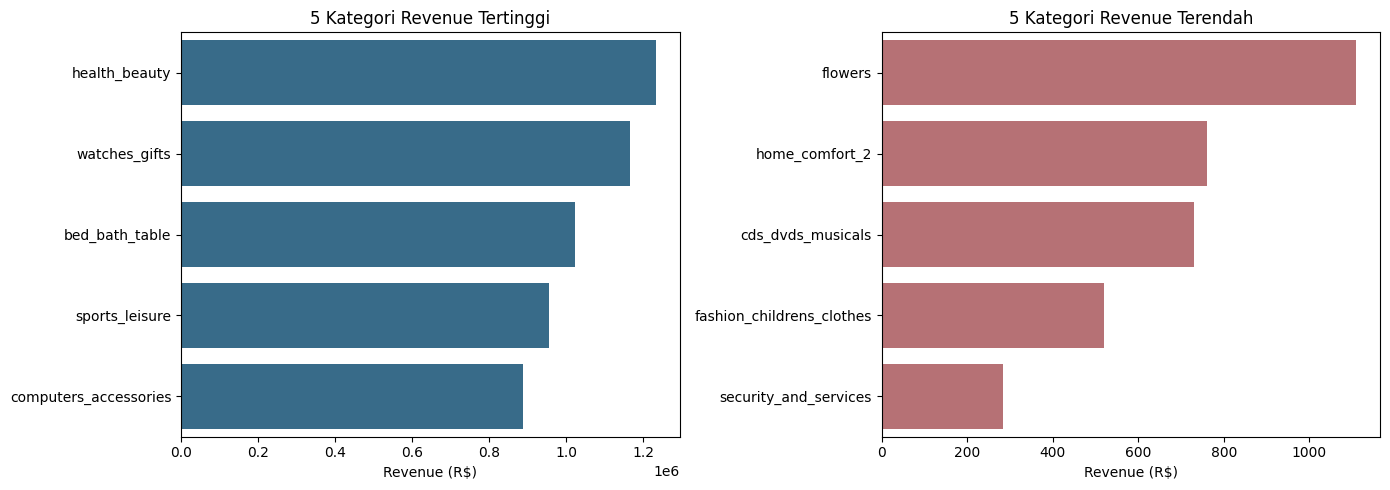

In [131]:
top5 = revenue.head(5); bottom5 = revenue.tail(5)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top5, x='total_revenue', y='product_category_name_english', ax=ax[0], color='#2a6f97')
ax[0].set_title('5 Kategori Revenue Tertinggi')
sns.barplot(data=bottom5, x='total_revenue', y='product_category_name_english', ax=ax[1], color='#c1666b')
ax[1].set_title('5 Kategori Revenue Terendah')
for a in ax: a.set_xlabel('Revenue (R$)'); a.set_ylabel('')
plt.tight_layout(); plt.show()

Health_beauty menjadi kategori dengan revenue tertinggi (BRL 1,23 juta), diikuti watches_gifts dan bed_bath_table. Lima kategori teratas menyumbang 39,8% dari total revenue. Peringkat revenue tidak sama dengan peringkat volume: bed_bath_table memiliki order terbanyak (9.272) dengan harga rata-rata BRL 93, sedangkan watches_gifts unggul karena harga rata-rata BRL 199. Kategori terendah, security_and_services, hanya mencatat 2 order dengan revenue BRL 283.

### Pertanyaan 2:

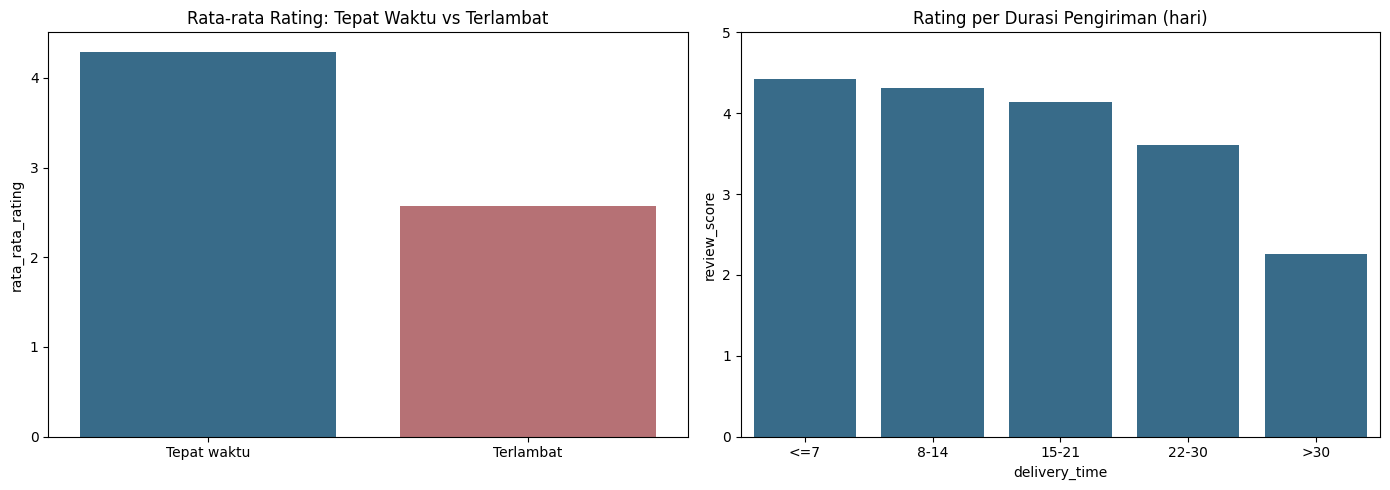

In [132]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=['Tepat waktu', 'Terlambat'], y=delivery_review['rata_rata_rating'],
            hue=['Tepat waktu', 'Terlambat'], palette=['#2a6f97', '#c1666b'], legend=False, ax=ax[0])
ax[0].set_title('Rata-rata Rating: Tepat Waktu vs Terlambat')
bins = pd.cut(order_level['delivery_time'], [0, 7, 14, 21, 30, 200], labels=['<=7', '8-14', '15-21', '22-30', '>30'])
by_bin = order_level.groupby(bins, observed=True)['review_score'].mean().reset_index()
sns.barplot(data=by_bin, x='delivery_time', y='review_score', ax=ax[1], color='#2a6f97')
ax[1].set_ylim(0, 5); ax[1].set_title('Rating per Durasi Pengiriman (hari)')
plt.tight_layout(); plt.show()

Segmen At Risk (24,6% pelanggan) menyumbang 41,2% total spending dan Big Spender Baru 39,2%, sehingga keduanya bersama-sama mencakup sekitar 80% spending. Segmen Loyal hanya 1,7% pelanggan (3,1% spending). Hanya 3,0% pelanggan yang melakukan pembelian ulang, artinya sekitar 97% pelanggan berbelanja satu kali.

### pertanyaan 3

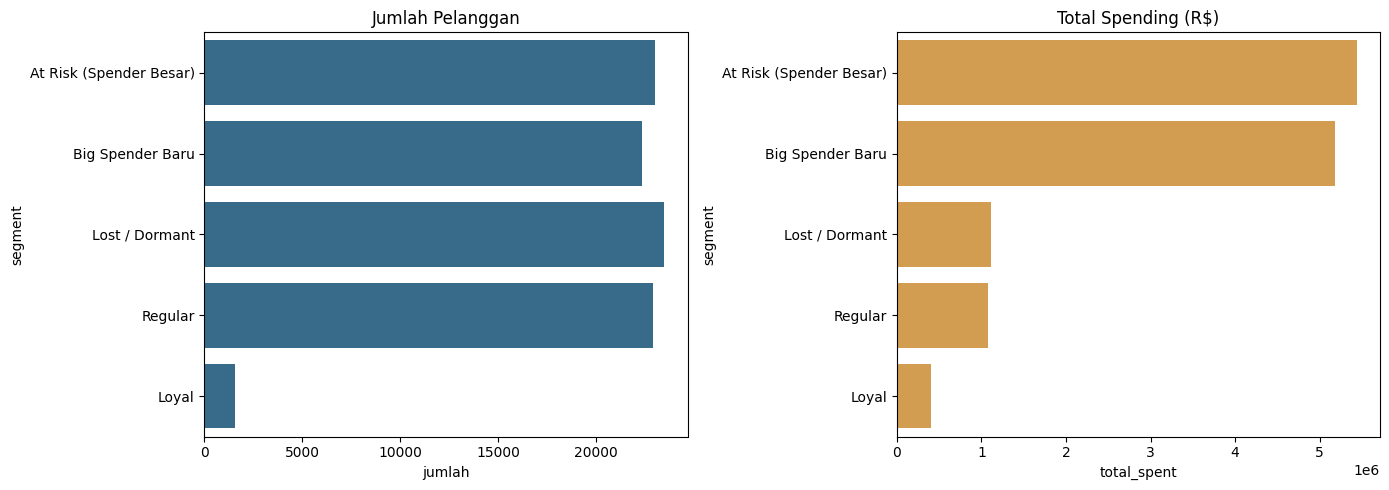

In [133]:
seg = rfm_df.groupby('segment').agg(jumlah=('customer_unique_id', 'count'), total_spent=('monetary', 'sum')).sort_values('total_spent', ascending=False).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=seg, x='jumlah', y='segment', ax=ax[0], color='#2a6f97'); ax[0].set_title('Jumlah Pelanggan')
sns.barplot(data=seg, x='total_spent', y='segment', ax=ax[1], color='#e9a03b'); ax[1].set_title('Total Spending (R$)')
plt.tight_layout(); plt.show()

Segmen At Risk (24,6% pelanggan) menyumbang 41,2% total spending dan Big Spender Baru 39,2%, sehingga keduanya bersama-sama mencakup sekitar 80% spending. Segmen Loyal hanya 1,7% pelanggan (3,1% spending). Sebanyak [Y]% pelanggan melakukan pembelian ulang.

## Analisis Lanjutan (Opsional)

## Conclusion & Recommendation

- Conclusion P1: Health_beauty, watches_gifts, dan bed_bath_table adalah kategori dengan revenue tertinggi, dan 5 kategori teratas menyumbang sekitar 40% revenue. Kategori terendah kontribusinya nyaris nol dengan hanya beberapa order.
- Conclusion P2: Keterlambatan menurunkan rating rata-rata dari 4,29 menjadi 2,57. Durasi pengiriman berkorelasi negatif sedang dengan rating (-0,33).
- Conclusion P3: Sekitar 97% pelanggan hanya berbelanja satu kali. Segmen At Risk dan Big Spender Baru menyumbang sekitar 80% spending, sementara Loyal hanya 1,7% pelanggan.

**Rekomendasi Action Item:**
- Perbaiki akurasi estimasi pengiriman dan pantau seller atau region dengan order terlambat tinggi, karena keterlambatan berasosiasi dengan rating yang jauh lebih rendah.
- Kirim voucher repeat-order ke segmen At Risk, karena segmen ini menyimpan 41% spending tapi sudah lama tidak belanja.
- Pertahankan stok dan promo di 5 kategori teratas, dan pertimbangkan bundling di watches_gifts karena revenuenya digerakkan harga tinggi, bukan volume.

In [134]:
import os
os.makedirs('dashboard', exist_ok=True)
cols = ['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'delivery_time',
        'is_late', 'review_score', 'price', 'product_category_name_english']
main_df = df[df['order_status'] == 'delivered'][cols].dropna(subset=['is_late']).copy()
main_df.to_csv('dashboard/main_data.csv', index=False)
print(main_df.shape)

(110189, 8)


In [135]:
from google.colab import files
files.download('dashboard/main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>